# The stage as an object

<div class="alert alert-info">

**Summary**

This lesson constructs the consumption stage of the portfolio–consumption model from its file and inspects the [[elaborated_stage|elaborated stage]], the Python object the package `bellman` constructs from it. You will read the stage file, construct the stage, and ask it in turn for its printed summary, its fields at the three perches, its [[builder|builders]], the inputs and outputs of one builder, that builder's mathematical statement, and a drawing. No earlier lesson is needed; the lesson assumes dynamic programming and the consumption–savings problem. It constructs only; nothing is evaluated or solved.

</div>

<div class="alert alert-success">

**Relationship with other documents**

**Formal account** — [Stages and perches](../../docs/bellman-calculus/03-Stages%20and%20perches.md): the stage, its perches and its backward and forward readings.

**Used by** — [Value functions and the backward builders](02-value-functions.ipynb), which opens the builders shown here, and the model walkthrough [Two stages, two orders](../models/cons-port/01-two-stages-two-orders.ipynb), which joins this stage to three others.

**See also** — [The stage](../../docs/Bellman-Sym/API/stage/01-the-stage.md): every attribute of the object; [the portfolio–consumption application](../../applications/cons-port/README.md): the model's files.

</div>

<div class="alert">

**Key terminology**

| Term | Meaning |
|---|---|
| [[elaborated_stage\|elaborated stage]] | The Python object the package constructs from a stage file. |
| [[builder]] | The operator a block of the stage file denotes. |
| [[signature]] | A builder's input and output wires, each with the set of objects it carries. |
| card | The printed statement of what a piece of a stage denotes. |
| sheet | The stage's one-page printed summary. |

</div>

A [[stage]] is one step of a [[period]]'s Bellman problem, with three [[perch|perches]], arrival, decision and continuation, each the information held at one point of the step; each quantity of the stage is a [[field]] known at one of them.

The household arrives with resources $\mathrm m$, its cash on hand. At the decision it chooses consumption $\mathrm c$ in $(0, \mathrm m_d]$: it can neither borrow nor consume more than it holds. It carries the rest to the continuation perch as savings, $\mathrm a = \mathrm m_d - \mathrm c$. Utility is $u(\mathrm c) = \mathrm c^{1-\rho}/(1-\rho)$, with relative risk aversion $\rho$; the formula divides by $1 - \rho$, so $\rho = 1$, which the file's declaration admits, is excluded by a condition the package records. The stage has no discount factor and no shock: in the full model, discounting is a stage of its own, and the risky return and income are drawn in the portfolio stage.

| In the file | Symbol | Meaning |
|---|---|---|
| `m`, `m_d` | $\mathrm m$, $\mathrm m_d$ | resources on arrival and at the decision, equal to each other |
| `c` | $\mathrm c$ | consumption |
| `a` | $\mathrm a$ | savings, at continuation |
| `V`, `dV` | $V$, $dV$ | the value and the marginal value, its derivative in the state |
| `V[>]`, `V[<]` | $V_\succ$, $V_\prec$ | the value at continuation and at arrival |
| `ρ` | $\rho$ | relative risk aversion |


The lesson writes only the two files of the interactive view of the stage opened at the end of the lesson, in the folder model-explorer beside it, and reads one file:

`applications/portfolio-choice/declaration/stages/cons/cons.bl`

The stage file names no other file: parameter values, numerical methods and settings are bound to a stage later, each from a file of its own. The first code cell imports the set-up module of the collection, checkout, which makes the package importable and sets the working directory to the repository root, so that the path above is read as written; it defines one function, explore, which opens the interactive view named above. The cell then imports the two functions the lesson calls.

In [1]:
import checkout
from bellman.stage import elaborate_stage, load_stage

## The stage file

`load_stage` reads a stage file into its **source record**, a Python dictionary that holds the file's text, its path and a digest of the text, a fingerprint of its exact characters. It parses nothing. The next cell reads the consumption stage and names its source record `source`.

In [2]:
source = load_stage("applications/portfolio-choice/declaration/stages/cons/cons.bl")

The record holds the text under `source["stage"]["text"]`; printing it shows the file as the package read it. After the header `@stage: cons` come the declarations: the set `Xm` of resources, the positive reals, and the set `Xa` of savings, the non-negative reals; the parameter `ρ`, in $[1, \infty)$, although the formula of utility excludes $\rho = 1$; utility `𝑢`, marginal utility `𝑑𝑢` and its inverse `𝑑𝑢𝑖𝑛𝑣`; and `Γ`, the feasible consumption $(0, x]$ at resources $x$. Five **blocks** follow, each a header in square brackets, naming the fields the block reads and writes and the perch of each (`!arvl`, `!dcsn`, `!cntn`), and a body in braces holding its equations.

The first two blocks read forward: `arvl_to_dcsn` sets $\mathrm m_d = \mathrm m$, and `dcsn_to_cntn` sets $\mathrm a = \mathrm m_d - \mathrm c$. The next two read backward: `cntn_to_dcsn` writes the value equation $V = u(\mathrm c) + V_\succ$ at a given consumption rule, the Bellman equation at the optimal one, and $dV = u'(\mathrm c)$, the envelope condition at the optimal rule, and `dcsn_to_arvl` passes both back to arrival unchanged. The fifth, `policy`, states the choice: its line marked `!doc` states the maximization for the reader and is no equation of the model, and the three lines below it give the choice through the Euler equation, written with the inverse of marginal utility as an inequality. The **clause** `⟂ a >= 0` after the inequality, read "complementary to", joins it to the borrowing limit $\mathrm a \ge 0$: the inequality is an equality wherever savings are positive, and at zero savings, where the limit binds, it only bounds consumption, which then equals resources ([Constraints](../../docs/Bellman-Sym/10-constraints.md) §4.3).

In [3]:
print(source["stage"]["text"])

@stage: cons

Xm := ℝ₊₊
Xa := ℝ₊

ρ : [1, inf)

𝑢(c : ℝ₊₊) := c^(1-ρ)/(1-ρ)         :: [id=util]
𝑑𝑢(c : ℝ₊₊) := c^(-ρ)               :: [id=marginal_utility]
Γ(x : ℝ₊₊) := (0, x]

[id=arvl_to_dcsn, (m : Xm, l : ℝ₊) : !arvl -> (m_d : Xm) : !dcsn] {
    m_d = m
}

[id=dcsn_to_cntn, (m_d, c : !ctrl @ ℝ₊₊) : !dcsn -> (a : Xa) : !cntn] {
    a = m_d - c
}

[id=cntn_to_dcsn, (V[>] : [-inf, inf) @ !vlu, c) : !cntn -> (V : [-inf, inf) @ !vlu) : !dcsn] {
    V        = 𝑢(c) + V[>]          :: [id=value]
    D_{m_d}V = 𝑑𝑢(c)                :: [id=marginal]
}

[id=dcsn_to_arvl, (V) : !dcsn -> (V[<] : ℝ @ !vlu) : !arvl] {
    V[<] = V                        :: [id=value]
}

[id=policy, (V[>] : [-inf, inf) @ !vlu) : !cntn -> (c : ℝ₊₊ @ !ctrl) : !dcsn] {
    c      = argmax_{cp : Γ(m_d)}(𝑢(cp) + V[>])   :: [id=optimality]
}



## The elaborated stage

**Elaboration** is the construction of the stage from its source record: the package parses the text, checks that each declaration and equation is well formed over the sets the file declares, records as conditions the memberships it cannot decide, and builds one Python object that holds the declarations, the blocks and the operators the blocks denote. `elaborate_stage` performs it. The next cell names the result `cons`, the name the file declares.

In [4]:
cons = elaborate_stage(source)

The stage displays itself in one line, its **short form**: the class of the object, the stage's name and its version.

In [5]:
cons

ElaboratedStage('cons', symbolic)

The version `symbolic` means that no parameter value, numerical method or numerical setting is bound yet; each binding returns a new version and leaves this one unchanged.

## The sheet

`view()` prints the stage's **sheet**, a one-page summary in labeled sections. The line under the title names the file the stage was constructed from: a **stage occurrence** is one use of a stage file at one position of a model, and a stage constructed alone, as here, is one occurrence. `PERCHES` lists the fields at each perch, marked ≺ for arrival, ∼ for decision and ≻ for continuation; each marginal value is declared by the file, with `!mrgnvl`, not computed. `FIELDS` groups the fields by role, and `BLOCKS` repeats each block's header, → for a forward block and ← for a backward one. `DEFINITIONS` counts the declarations by kind. A **correspondence** is a map whose value is a set, here `Γ`. A **law of motion** is the map a forward block states, from the state at one perch to the state at the next. A **value aggregator** is the map a backward block states, which combines the continuation value with the state and the control. A **kernel** is the mathematical data an operation of a builder, described below, uses: a law of motion for a pullback or a push-forward, a value aggregator for an aggregation, a probability distribution for an expectation. `GRAPHS` reports the graphs built in each direction: an **initial diagram**, whose framed regions are the blocks, each holding one box per line, and whose wires are fields, and a **builders graph**, whose boxes are the builders described below. `BINDINGS` shows that no parameter value, method or setting is bound, beside the verb that binds each; `DIRECTIONS` gives the order in which the perches are read.

In [6]:
cons.view()

BELLMAN-SYM / STAGE cons                                  [VERSION = SYMBOLIC]
a stage occurrence of
applications/portfolio-choice/declaration/stages/cons/cons.bl
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

PERCHES ──────────────────────────────────────────────────────────────────────
  ≺ arrival        m≺ state, l≺ state, V≺ value
  ∼ decision       m_d state, c control, V value
  ≻ continuation   a≻ state, V≻ value

FIELDS ───────────────────────────────────────────────────────────────────────
  states           m≺ at arrival, l≺ at arrival, m_d at decision, a≻ at
                   continuation
  controls         c at decision
  values           V at every perch
  shocks           none

BLOCKS ───────────────────────────────────────────────────────────────────────
  → arvl_to_dcsn   (m≺, l≺) : !arvl -> (m_d) : !dcsn
  → dcsn_to_cntn   (m_d) : !dcsn, at c -> (a≻) : !cntn
  ← cntn_to_dcsn   (V≻) : !cntn, at c -> (V) : !dcsn
  ← dcsn_to_arvl   (V) : 

## The three perches

`fields()` answers a table of every field the stage names: its identity, written `stage:perch:name`, its perch, its role and the set of its values. Read the perch column: resources are the state at arrival and at the decision, savings the state at continuation, and consumption the one control, at the decision; each perch also carries a value and a marginal value.

In [7]:
cons.fields()

cons:arvl:m     ≺ arvl  state  in Xm
cons:arvl:l     ≺ arvl  state  in ℝ₊
cons:dcsn:m_d   ∼ dcsn  state  in Xm
cons:dcsn:c     ∼ dcsn  control  in ℝ₊₊
cons:cntn:a     ≻ cntn  state  in Xa
cons:cntn:V     ≻ cntn  value  in [-inf, inf)
cons:dcsn:V     ∼ dcsn  value  in [-inf, inf)
cons:arvl:V     ≺ arvl  value  in ℝ

## The builders

A [[builder]] is the operator a block denotes. A backward builder maps value functions at one perch to value functions at the perch before it, and a forward builder maps the distribution of the state at one perch to its distribution at the next; the policy builder maps the continuation value and marginal value to the consumption rules that solve the choice. The **wires** of a builders graph carry these functions or distributions between its builders. The stage's `builder` reaches each builder by the ordered pair of perches it joins: the perch of the fields its block reads, then the perch of the fields it writes. It also holds the two builders graphs, `builder.bwd`, the backward builders used in solution, and `builder.fwd`, the forward builders used in simulation. Both graphs hold the operators symbolically, and neither solves nor simulates the model. `list()` names each of the five builders by its block, one to a line, with the pair it joins, written as an arrow from the first perch to the second, and the word of its direction, `fwd` or `bwd`. The policy block joins the same two perches as the block `cntn_to_dcsn`, so the policy builder's line gives its own key, `policy`, in place of the pair.

In [8]:
cons.builder.list()

arvl_to_dcsn   arvl → dcsn, fwd
dcsn_to_cntn   dcsn → cntn, fwd
cntn_to_dcsn   cntn → dcsn, bwd
dcsn_to_arvl   dcsn → arvl, bwd
policy         policy, bwd

Each of the arrival and decision perches, `cons.arvl` and `cons.dcsn`, reaches through its `builder` the builders of the edge that leaves it, the step from that perch to the next, whatever the block is called. Of these, `bwd` is the backward builder: it constructs the value functions at the perch from those at the next perch. So `cons.dcsn.builder.bwd` is the decision builder, `cons.builder["cntn", "dcsn"]`: the builder of the block `cntn_to_dcsn`, which gives the value $V$ and the marginal value $dV$ at the decision from the continuation value $V_\succ$. Its [[signature#Builder signatures and mathematical signatures|signature]] lists its input and output wires, each with its **carrier**, the set of functions the wire carries: functions of savings in `Xa` in, functions of resources in `Xm` out.

In [9]:
cons.dcsn.builder.bwd.signature()

in         𝑉≻ : Xa → [−∞, ∞)
out        𝑉 : Xm → [−∞, ∞)

Consumption is not among the wires: the builder is one operator for each consumption rule, and its card, below, names the rule.

## The card of a builder

A **card** is the printed statement of the mathematical object a piece of the stage denotes, and `denote()` answers it. Read the decision builder's card from the top, heading by heading; `Signature` repeats the wires above. `At` names the consumption rule $c$ at which the operator is stated, a function of resources with $c(\mathrm m_d) \in \Gamma(\mathrm m_d)$. `Where` defines $g_{\succ,c}$, the law of motion with the rule substituted. `Operations` lists, in order, the three operations the builder composes: the **pullback**, which composes $V_\succ$ with $g_{\succ,c}$, so that the continuation value is read at the savings each level of resources leads to; the **aggregation**, which applies the block's two equations at each point; and the **evaluation**, which returns the result as $V$ and $dV$. Each entry gives its number and kind, the wires it reads after `in:`, where `(1)` is the output of entry 1, the wires it writes after `out:`, and its rule after `rule:`. `Conditions` states what the construction assumes and does not verify: that each result lies in its declared set. Below the light line, the thin line across the whole card, `Source` names the file and quotes its lines 22 and 23, and `Definitions referenced` names the declarations the card cites.

In [10]:
cons.dcsn.builder.bwd.denote()

STAGE cons / BACKWARD BUILDER cntn → dcsn (cntn_to_dcsn)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   𝑉≻  : Xa → [−∞, ∞)
       ───────────────────────────────────────────────────
  out  𝑉   : Xm → [−∞, ∞)

At
  𝑐  : Xm → ℝ₊₊,  𝑐(m_d) ∈ Γ(m_d)

Operations
  1  Pullback
     in: 𝑉≻                             out: 𝑉≻ ∘ 𝑔≻(·, 𝑐)
     ─────────────────────────────────────────────────────
     rule: (𝑉≻ ∘ 𝑔≻(·, 𝑐))(m_d) = 𝑉≻(𝑔≻(m_d, 𝑐(m_d)))

  2  Aggregation
     in: (1)                            out: 𝑉
     ─────────────────────────────────────────────────────
     rule: 𝑉(m_d) = 𝑢(𝑐(m_d)) + 𝑉≻(𝑔≻(m_d, 𝑐(m_d)))

  3  Evaluation
     in: 𝑉                              out: 𝑉
     ─────────────────────────────────────────────────────
     rule: 𝑉 : Xm → [−∞, ∞)
           D_{m_d}𝑉(m_d) = 𝑑𝑢(𝑐(m_d))

Conditions
  Aggregation  𝑉(m_d) ∈ [−∞, ∞)
──────────────────────────────────────────────────────────────────────────────
Source  cons.bl
  2

The first line after the aggregation's `rule:` is the stage's value equation at a given consumption rule, $V(\mathrm m_d) = u(c(\mathrm m_d)) + V_\succ(\mathrm m_d - c(\mathrm m_d))$, and its Bellman equation at the optimal one; it has no discount factor, since discounting is a stage of its own.

## The drawing

`diagram()` lays a graph out as a picture, here the backward builders graph. Each framed region is one builder, labeled by its block's name and holding the operations its card lists; a dashed box is an evaluation, labeled by the outputs it produces, such as `𝑉(m_d), 𝑑𝑉(m_d)` in the decision builder; and the label on an arrow is the function the wire carries. The continuation value and marginal value enter at the top; the arrival value and marginal value and the consumption rule leave at the bottom.

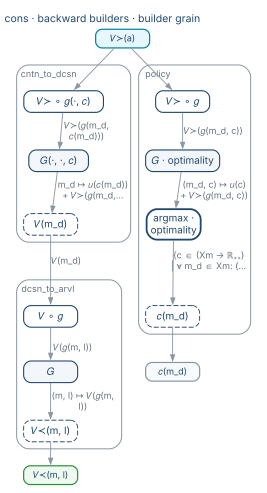

In [11]:
cons.builder.bwd.diagram()

The decision builder, at the upper left, holds the pullback, the aggregation and the evaluation of the card above, and no wire joins the policy builder's output to it, because it is stated at each consumption rule.

`checkout.explore` shows the same graph in [Google's Model Explorer](https://github.com/google-ai-edge/model-explorer), an interactive viewer in which each builder is a frame opened to the operations it holds, and in which selecting an operation shows, in a side panel, its kernel, its method once one is bound, and the wires it reads and writes, each with its perch and its type. The drawing above is the picture saved with the lesson, since the view opens only when the lesson is run: the saved output of the next cell is the paths of the two files it writes into the folder `model-explorer` beside the lesson.

In [12]:
checkout.explore(cons)

tutorials/getting-started/model-explorer/cons.graph.json
tutorials/getting-started/model-explorer/cons.edge-overlays.json
